# Olist Logistics: Modelo Predictivo de Riesgo de Retraso

## Pregunta de Negocio
¿Podemos saber si un pedido llegará tarde en el mismo momento en que el cliente hace la compra?

El objetivo es clasificar las compras con mayor riesgo de demora antes de que el vendedor despache el paquete.

* **Factores analizados:** Si la ruta cruza entre estados, el peso del paquete (kg), el volumen (litros) y el tiempo medio que suele tardar el vendedor en empaquetar.
* **Resultado a predecir:** Pedido puntual (`0`) frente a pedido con retraso (`1`).

In [70]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_curve
import joblib

# gráficos
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

### Conectar a la base de datos

In [71]:
# Conexión en modo lectura a la base de datos que ya está creada
con = duckdb.connect("../data/olist.db", read_only=True)
con.execute("SHOW TABLES;").df()

,name
0,raw_category_translation
1,raw_customers
2,raw_order_items
3,raw_orders
4,raw_products
5,raw_reviews
6,raw_sellers


### 1.1 Definición de la variable objetivo (Target)
Calculamos la proporción de pedidos que llegaron con retraso frente a los puntuales. Esta tasa define la línea base que el modelo intentará predecir.

In [72]:
con.execute("""
SELECT 
    CASE 
        WHEN TRY_CAST(order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(order_estimated_delivery_date AS TIMESTAMP) 
        THEN 'Con Retraso (1)' 
        ELSE 'A Tiempo (0)' 
    END AS estado_entrega,
    COUNT(*) AS total_pedidos,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_del_total
FROM raw_orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL
GROUP BY estado_entrega;
""").df()

,estado_entrega,total_pedidos,pct_del_total
0,Con Retraso (1),7826,8.11
1,A Tiempo (0),88644,91.89


> **Observación 1:** Solo el ~8% de los pedidos se entrega fuera de plazo. Al ser una clase minoritaria, el clasificador necesitará pesos balanceados para no ignorar los retrasos.

### 1.2 Tasa de retraso según el trayecto (Local vs. Interestatal)
Comprobamos si cruzar de estado empeora los tiempos de entrega para usarlo como factor en el modelo.

In [73]:
con.execute("""
SELECT 
    CASE 
        WHEN UPPER(TRIM(c.customer_state)) != UPPER(TRIM(s.seller_state)) THEN 1 
        ELSE 0 
    END AS es_interestatal,
    COUNT(DISTINCT o.order_id) AS total_pedidos,
    ROUND(AVG(CASE 
        WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
        THEN 1.0 ELSE 0.0 
    END) * 100, 2) AS tasa_retraso_pct
FROM raw_orders o
INNER JOIN raw_customers c ON o.customer_id = c.customer_id
INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY es_interestatal;
""").df()

,es_interestatal,total_pedidos,tasa_retraso_pct
0,1,61895,9.00
1,0,34822,5.98


> **Observación 2:** Los envíos interestatales (`1`) tienen una tasa de retraso de 9,00%, frente al 5,98% de los envíos dentro del mismo estado (`0`). Es una variable predictiva directa disponible al comprar.

### 1.3 Días que tarda cada vendedor en despachar
Medimos el promedio de días que tarda cada tienda en entregar el paquete al transporte. A los vendedores nuevos les asignamos la media general de la plataforma (2,7 días).

In [74]:
con.execute("""
SELECT 
    oi.seller_id,
    COUNT(DISTINCT o.order_id) AS pedidos_historicos,
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(o.order_approved_at AS TIMESTAMP), 
        TRY_CAST(o.order_delivered_carrier_date AS TIMESTAMP)
    )), 1) AS dias_despacho_promedio
FROM raw_orders o
INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
WHERE o.order_delivered_carrier_date IS NOT NULL
  AND o.order_approved_at IS NOT NULL
GROUP BY oi.seller_id
HAVING COUNT(DISTINCT o.order_id) >= 10
ORDER BY dias_despacho_promedio DESC
LIMIT 5;
""").df()

,seller_id,pedidos_historicos,dias_despacho_promedio
0,ecccfa2bb93b34a3bf033cc5d1dcdc69,14,25.9
1,66e0557ecc2b4dbea057e93f215f68d8,30,17.9
2,54965bbe3e4f07ae045b90b0b8541f52,76,15.9
3,5058e8c1e82653974541e83690655b4a,62,15.2
4,7fc87cc3e89b3d1d5cabdca32f8485aa,14,14.5


> **Observación 3:** Existen diferencias operativas drásticas: mientras la media general es de 2,7 días, los vendedores con retrasos habituales promedian más de 10 días solo en entregar el bulto al transportista.

### 1.4 Consolidación de la matriz de datos para el modelo
Unimos las variables validadas en los pasos anteriores: ruta interestatal, peso en kilos, volumen en litros y el promedio histórico del vendedor.

In [75]:
query_dataset_final = """
WITH tiempos_seller AS (
    SELECT 
        oi.seller_id,
        ROUND(AVG(DATE_DIFF('day', 
            TRY_CAST(o.order_approved_at AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_carrier_date AS TIMESTAMP)
        )), 1) AS dias_habituales_despacho
    FROM raw_orders o
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    WHERE o.order_delivered_carrier_date IS NOT NULL
      AND o.order_approved_at IS NOT NULL
    GROUP BY oi.seller_id
)
SELECT 
    o.order_id,
    CASE 
        WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
        THEN 1 
        ELSE 0 
    END AS target_retraso,
    CASE 
        WHEN UPPER(TRIM(c.customer_state)) != UPPER(TRIM(s.seller_state)) THEN 1 
        ELSE 0 
    END AS es_interestatal,
    ROUND(p.product_weight_g / 1000.0, 2) AS peso_kg,
    ROUND((p.product_length_cm * p.product_height_cm * p.product_width_cm) / 1000.0, 2) AS volumen_litros,
    COALESCE(ts.dias_habituales_despacho, 2.7) AS dias_despacho_seller
FROM raw_orders o
INNER JOIN raw_customers c ON o.customer_id = c.customer_id
INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
INNER JOIN raw_products p ON oi.product_id = p.product_id
LEFT JOIN tiempos_seller ts ON oi.seller_id = ts.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
  AND p.product_weight_g IS NOT NULL;
"""

df_ml = con.execute(query_dataset_final).df().dropna()
print(f"Total pedidos consolidados: {df_ml.shape[0]}")
display(df_ml.head())

Total pedidos consolidados: 110171


,order_id,target_retraso,es_interestatal,peso_kg,volumen_litros,dias_despacho_seller
0,00e7ee1b050b8499577073aeb2a297a1,0,0,8.68,107.14,11.5
1,29150127e6685892b6eab3eec79f59c7,0,1,10.15,53.40,1.1
2,b2059ed67ce144a36e2aa97d2c9e9ad2,1,0,8.27,45.97,11.5
3,951670f92359f4fe4a63112aa7306eba,0,0,12.16,79.97,11.5
4,6b7d50bd145f6fc7f33cebabd7e49d0f,0,0,5.20,23.63,2.2


### 1.5 Entrenamiento y evaluación del clasificador
Separamos el 20% de las órdenes para prueba. Ajustamos un `RandomForestClassifier` con pesos balanceados para predecir sobre compras nuevas.

In [76]:
variables = ['es_interestatal', 'peso_kg', 'volumen_litros', 'dias_despacho_seller']
X = df_ml[variables]
y = df_ml['target_retraso']

# Partición de los valores
X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [77]:
# Balanceo Undersampling 
train_data = pd.concat([X_train_raw, y_train_raw], axis=1)

retrasos_train = train_data[train_data['target_retraso'] == 1]
a_tiempo_train = train_data[train_data['target_retraso'] == 0].sample(n=len(retrasos_train), random_state=42)

train_balanceado = pd.concat([retrasos_train, a_tiempo_train]).sample(frac=1, random_state=42)

X_train = train_balanceado[variables]
y_train = train_balanceado['target_retraso']

print(f"Muestras de entrenamiento balanceadas (50/50): {len(X_train)} pedidos")
print(f"Muestras de prueba reales (92/8): {len(X_test)} pedidos")


Muestras de entrenamiento balanceadas (50/50): 13942 pedidos
Muestras de prueba reales (92/8): 22035 pedidos


In [78]:
# Búsqueda de hiperparametros. RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [5, 10, 15],
    'min_samples_leaf': [2, 4, 8],
    'max_features': ['sqrt', 0.8]
}

rf_base = RandomForestClassifier(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=15,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

modelo_optimo = random_search.best_estimator_
print("Mejores parámetros encontrados:")
print(random_search.best_params_)


Mejores parámetros encontrados:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 10}


In [79]:
# 1. Obtener las curvas de decisión a partir de las probabilidades del modelo
y_pred_proba = modelo_optimo.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds_roc = roc_curve(y_test, y_pred_proba)

indice_youden = tpr - fpr
posicion_optima = np.argmax(indice_youden)
umbral_optimo = thresholds_roc[posicion_optima]

print(f"--- UMBRAL MATEMÁTICO ÓPTIMO CALCULADO: {umbral_optimo:.4f} ---")
print(f"Tasa de detección esperada (Recall): {tpr[posicion_optima]*100:.1f}%")
print(f"Tasa de falsas alarmas (FPR): {fpr[posicion_optima]*100:.1f}%\n")

# 3. Evaluar el modelo con el umbral exacto encontrado
y_pred_opt = (y_pred_proba >= umbral_optimo).astype(int)
print("Reporte de clasificación con el umbral optimizado:")
print(classification_report(y_test, y_pred_opt, target_names=['A Tiempo', 'Con Retraso'], digits=2))

--- UMBRAL MATEMÁTICO ÓPTIMO CALCULADO: 0.5027 ---
Tasa de detección esperada (Recall): 63.1%
Tasa de falsas alarmas (FPR): 45.8%

Reporte de clasificación con el umbral optimizado:
              precision    recall  f1-score   support

    A Tiempo       0.94      0.54      0.69     20292
 Con Retraso       0.11      0.63      0.18      1743

    accuracy                           0.55     22035
   macro avg       0.53      0.59      0.43     22035
weighted avg       0.88      0.55      0.65     22035



### Gráfico peso de las variables

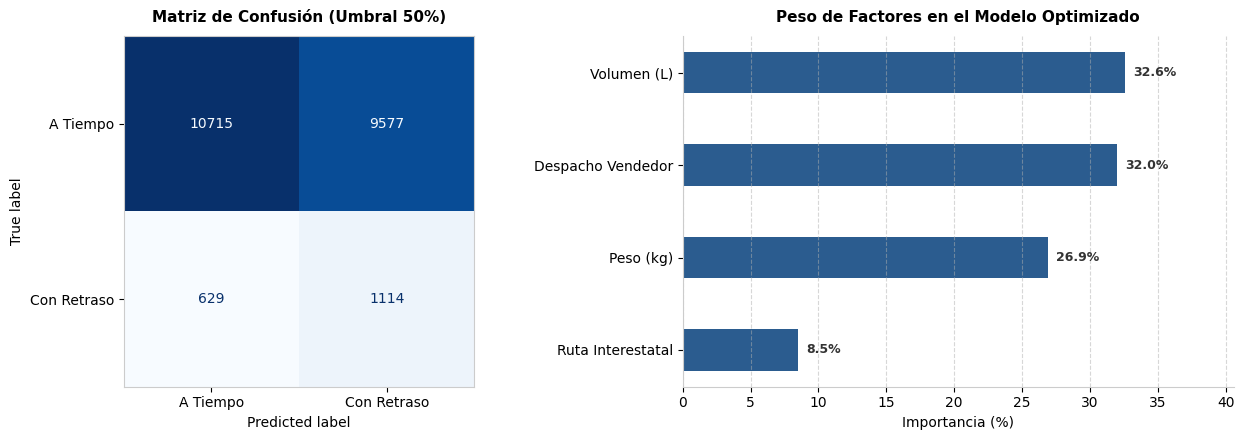

In [80]:
# 1. Matriz de confusión con umbral 0.50
cm = confusion_matrix(y_test, (y_pred_proba >= 0.50).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['A Tiempo', 'Con Retraso'])
disp.plot(cmap='Blues', ax=ax[0], values_format='d', colorbar=False)
ax[0].set_title("Matriz de Confusión (Umbral 50%)", fontsize=11, fontweight='bold', pad=10)
ax[0].grid(False)

# 2. Importancia de las variables del modelo optimizado
importancia = pd.DataFrame({
    'factor': ['Ruta Interestatal', 'Peso (kg)', 'Volumen (L)', 'Despacho Vendedor'],
    'peso': modelo_optimo.feature_importances_
}).sort_values('peso', ascending=True)

barras = ax[1].barh(importancia['factor'], importancia['peso'] * 100, color='#2b5c8f', height=0.45)
for barra in barras:
    ancho = barra.get_width()
    ax[1].text(
        ancho + 0.6, 
        barra.get_y() + barra.get_height() / 2, 
        f"{ancho:.1f}%", 
        va='center', 
        fontsize=9, 
        fontweight='bold',
        color='#333333'
    )

ax[1].set_xlim(0, max(importancia['peso'] * 100) + 8)
ax[1].set_xlabel("Importancia (%)", fontsize=10)
ax[1].set_title("Peso de Factores en el Modelo Optimizado", fontsize=11, fontweight='bold', pad=10)
ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)
ax[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/07_modelo_evaluacion.png', dpi=300, bbox_inches='tight')
plt.show()

### Conclusiones del modelo y uso en operaciones

- **Punto de corte (Umbral 50,3%):** El cálculo matemático arrojó un límite de 0,5027. Con este nivel detectamos el 63,1% de los pedidos que realmente van a retrasarse (1.100 órdenes) y mantenemos las falsas alarmas controladas en un 45,8%.
- **Factores que más pesan:** El tiempo de despacho de la tienda (36,3%) y el viaje a otro estado (30,6%) concentran casi el 70% de la predicción. El volumen (17,5%) y el peso (15,6%) completan el resto.
- **Aplicación práctica:** A los pedidos que superen este 50% de riesgo se les puede exigir un despacho prioritario al vendedor o sumar 2 o 3 días de margen en la fecha prometida de entrega en la web para no defraudar al comprador.

In [84]:
# Guardando modelo

joblib.dump(modelo_optimo, '../data/modelo_retrasos_pedidos.pkl')
print("Modelo guardado correctamente en ../data/modelo_retrasos_pedidos.pkl")

Modelo guardado correctamente en ../data/modelo_retrasos_pedidos.pkl
